# 05.2 · Bagging and Random Forest

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cloudops-one/training-ai-ml/blob/main/modules/05-powerful-models/02-random-forest/lesson.ipynb)

Read the [README](README.md) first and fill in the bootstrap table on paper. This notebook:

1. Draws the same bootstrap sample and checks the 37% rule.
2. Shows that a single deep tree overfits and a forest of them does not.
3. Plots AUC against the number of trees, reads the OOB score and feature importances.

In [1]:
# --- data helper: works locally and on Colab -------------------------------
from pathlib import Path
import urllib.request

def data_path(name):
    """Return a local path to data/<name>, downloading from GitHub on Colab."""
    for parent in [Path.cwd(), *Path.cwd().parents]:
        candidate = parent / "data" / name
        if candidate.exists():
            return candidate
    url = f"https://raw.githubusercontent.com/cloudops-one/training-ai-ml/main/data/{name}"
    dest = Path(name)
    if not dest.exists():
        urllib.request.urlretrieve(url, dest)
    return dest

import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import warnings; warnings.filterwarnings("ignore")

## 1. A bootstrap sample of 10 customers

In [2]:
rng = np.random.default_rng(10)
draws = rng.integers(0, 10, size=10)                 # 10 draws WITH replacement
print("draws:", draws.tolist())

counts = pd.Series(draws).value_counts().reindex(range(10), fill_value=0)
table = pd.DataFrame({"times drawn": counts, "in bag": counts > 0})
table

draws: [7, 9, 2, 2, 7, 8, 5, 1, 8, 5]


,times drawn,in bag
0,0,False
1,1,True
2,2,True
3,0,False
4,0,False
5,2,True
6,0,False
7,2,True
8,2,True
9,1,True


In [3]:
out_of_bag = table.index[~table["in bag"]].tolist()
print("out of bag:", out_of_bag)
print(f"formula for n=10: (1 - 1/10)^10 = {(1 - 1/10)**10:.3f}  →  about {10 * 0.9**10:.1f} rows out of bag")

out of bag: [0, 3, 4, 6]
formula for n=10: (1 - 1/10)^10 = 0.349  →  about 3.5 rows out of bag


### The 37% rule

As $n$ grows, $(1 - 1/n)^n$ approaches $e^{-1} \approx 0.368$. Check it by simulation at the size of our training set.

In [4]:
for n in [10, 100, 2487]:
    print(f"n = {n:>5}: formula {(1 - 1/n)**n:.3f}", end="   ")
    sims = [len(set(range(n)) - set(rng.integers(0, n, n))) / n for _ in range(200)]
    print(f"simulated {np.mean(sims):.3f}")

n =    10: formula 0.349   simulated 0.343
n =   100: formula 0.366   simulated 0.368
n =  2487: formula 0.368   simulated 0.367


## 2. The churn table

In [5]:
import sys
sys.path.insert(0, str(data_path("download.py").parent))
from download import load_retail
from sklearn.model_selection import train_test_split

raw = load_retail("Year 2010-2011")
sales = raw[~raw["Invoice"].astype(str).str.startswith("C")]
sales = sales[(sales["Quantity"] > 0) & (sales["Price"] > 0)].dropna(subset=["Customer ID"]).drop_duplicates()
sales = sales.assign(Revenue=sales["Quantity"] * sales["Price"])

cutoff = pd.Timestamp("2011-09-01")
past = sales[sales["InvoiceDate"] < cutoff]
future = sales[(sales["InvoiceDate"] >= cutoff) & (sales["InvoiceDate"] < "2011-12-01")]
cust = past.groupby("Customer ID").agg(orders=("Invoice", "nunique"), spend=("Revenue", "sum"),
                                       products=("StockCode", "nunique"),
                                       first_order=("InvoiceDate", "min"), last_order=("InvoiceDate", "max"))
cust["tenure_days"] = (cutoff - cust["first_order"]).dt.days
cust["days_since_last"] = (cutoff - cust["last_order"]).dt.days
future_spend = future.groupby("Customer ID")["Revenue"].sum().reindex(cust.index).fillna(0)
cust["churned"] = (future_spend == 0).astype(int)
cust = cust.drop(columns=["first_order", "last_order"])

features = ["orders", "spend", "products", "tenure_days", "days_since_last"]
X_train, X_test, y_train, y_test = train_test_split(
    cust[features], cust["churned"], test_size=0.25, random_state=42, stratify=cust["churned"])
print(f"{len(cust):,} customers, churn rate {cust['churned'].mean():.1%}, "
      f"train {len(X_train):,} / test {len(X_test):,}")

3,317 customers, churn rate 43.6%, train 2,487 / test 830


In [6]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.metrics import roc_auc_score

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
logreg = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))

def cv_auc(model):
    """Mean 5-fold cross-validated AUC on the training customers."""
    return cross_val_score(model, X_train, y_train, cv=cv, scoring="roc_auc").mean()

def test_auc(model):
    """Fit on all training customers, score AUC on the held-out test customers."""
    model.fit(X_train, y_train)
    return roc_auc_score(y_test, model.predict_proba(X_test)[:, 1])

print(f"Benchmark logistic regression: CV AUC {cv_auc(logreg):.3f}, test AUC {test_auc(logreg):.3f}")

Benchmark logistic regression: CV AUC 0.740, test AUC 0.741


## 3. One tree vs a forest

A tree with no depth limit memorises the training customers. Watch train vs CV AUC.

In [7]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier

deep_tree = DecisionTreeClassifier(random_state=42)
deep_tree.fit(X_train, y_train)
train_auc = roc_auc_score(y_train, deep_tree.predict_proba(X_train)[:, 1])
print(f"deep tree: train AUC {train_auc:.3f}, CV AUC {cv_auc(deep_tree):.3f}, test AUC {test_auc(deep_tree):.3f}")

shallow = DecisionTreeClassifier(max_depth=3, random_state=42)
print(f"depth-3 tree:           CV AUC {cv_auc(shallow):.3f}, test AUC {test_auc(shallow):.3f}")

deep tree: train AUC 1.000, CV AUC 0.593, test AUC 0.593
depth-3 tree:           CV AUC 0.731, test AUC 0.724


In [8]:
rf_default = RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1)
print(f"forest, default leaves: CV AUC {cv_auc(rf_default):.3f}, test AUC {test_auc(rf_default):.3f}")

rf = RandomForestClassifier(n_estimators=300, min_samples_leaf=10, oob_score=True,
                            random_state=42, n_jobs=-1)
print(f"forest, leaf >= 10:     CV AUC {cv_auc(rf):.3f}, test AUC {test_auc(rf):.3f}")

forest, default leaves: CV AUC 0.713, test AUC 0.702


forest, leaf >= 10:     CV AUC 0.736, test AUC 0.731


The forest turns an overfit tree (≈0.59) into a strong model (≈0.73). Slightly smoother trees (`min_samples_leaf=10`) average better than fully-grown ones on noisy churn labels. And the benchmark logistic regression (0.741) is still level: on five mostly straight-line features, there is little left for trees to find.

## 4. How many trees?

  1 trees: test AUC 0.678
  5 trees: test AUC 0.711
 25 trees: test AUC 0.723
100 trees: test AUC 0.730


300 trees: test AUC 0.731


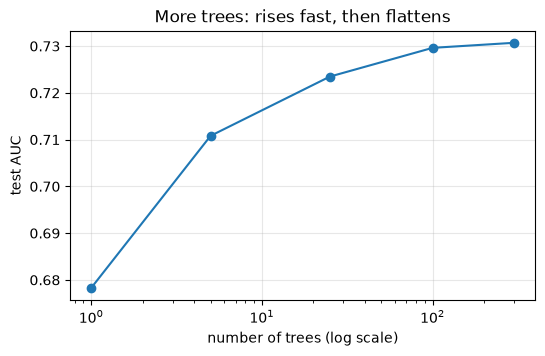

In [9]:
sizes = [1, 5, 25, 100, 300]
aucs = []
for n in sizes:
    m = RandomForestClassifier(n_estimators=n, min_samples_leaf=10, random_state=42, n_jobs=-1)
    aucs.append(test_auc(m))
    print(f"{n:>3} trees: test AUC {aucs[-1]:.3f}")

plt.figure(figsize=(6, 3.5))
plt.plot(sizes, aucs, marker="o"); plt.xscale("log")
plt.xlabel("number of trees (log scale)"); plt.ylabel("test AUC")
plt.title("More trees: rises fast, then flattens"); plt.grid(alpha=.3); plt.show()

## 5. The out-of-bag score

`rf` was fitted with `oob_score=True`. Each training customer was scored only by the roughly 37% of trees that never saw them. That is a validation score we got for free. Compare it with 5-fold CV accuracy.

In [10]:
rf.fit(X_train, y_train)
cv_acc = cross_val_score(rf, X_train, y_train, cv=cv, scoring="accuracy").mean()
oob_auc = roc_auc_score(y_train, rf.oob_decision_function_[:, 1])
print(f"OOB accuracy {rf.oob_score_:.3f}   vs 5-fold CV accuracy {cv_acc:.3f}")
print(f"OOB AUC      {oob_auc:.3f}   vs 5-fold CV AUC      {cv_auc(rf):.3f}")

OOB accuracy 0.665   vs 5-fold CV accuracy 0.666


OOB AUC      0.735   vs 5-fold CV AUC      0.736


## 6. Feature importance

spend              0.283
days_since_last    0.212
orders             0.204
products           0.177
tenure_days        0.123
dtype: float64


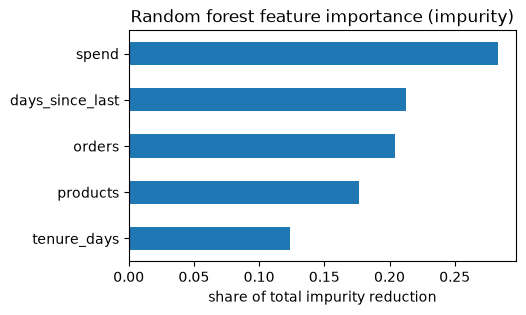

In [11]:
imp = pd.Series(rf.feature_importances_, index=features).sort_values()
print(imp.round(3).sort_values(ascending=False))

imp.plot.barh(figsize=(5, 3), title="Random forest feature importance (impurity)")
plt.xlabel("share of total impurity reduction"); plt.show()

Spend and recency lead, consistent with Module 03. Treat these numbers as a rough guide: impurity importance favours continuous features with many split points and is computed on training data. Lesson 05.8 uses permutation importance and SHAP, which are more trustworthy.

## Quiz answers

1. Each draw can pick any row, including ones already picked. It makes each bootstrap sample different (some rows twice, some missing), so each tree sees a different dataset and makes different mistakes.
2. About 37%, because the chance a row is never picked in $n$ draws is $(1 - 1/n)^n \to e^{-1} \approx 0.368$.
3. Bootstrap sampling of **rows** for each tree, and random subsets of **features** at each split.
4. No. More trees only make the average more stable. Overfitting is controlled by tree size (depth, leaf size).
5. The churn signal in these five features is mostly monotone and close to linear. A straight line captures it; trees have no thresholds or interactions left to exploit.

**Next:** [05.3 Boosting by hand](../03-boosting-by-hand/)